# ECON 524 — Lab: Debiased Machine Learning I
## Regularization bias, Neyman orthogonality, cross-fitting, and model-based DML

**Friday, November 6, 2026 · 50 minutes** · Lab instructor: Joel Reyes Mora

Covers **Lecture 4, Sections 1–2 (slides 4–25)**. Next Friday (Nov 13) we do Section 3: DML via the Riesz representer.

---

**Why this lab matters.** Every causal question this semester (ATE, LATE, DiD) ends up needing a *nuisance* function — a regression of $Y$ or $D$ on many controls $Z$. With high-dimensional $Z$ we must estimate it with ML. ML is built to **predict**, and the bias it accepts for good prediction (shrinkage, overfitting) leaks into the causal parameter. DML is the recipe that stops the leak. Its two ingredients:

| Ingredient | Bias it removes | Slides |
|---|---|---|
| **Neyman-orthogonal score** | regularization bias (e.g., LASSO shrinkage / omitted controls) | 6–8, 14–16, 20–21 |
| **Cross-fitting** | overfitting bias (the learner memorizes $Y_i$) | 9–12 |

**Plan**

| Block | Time | Slides |
|---|---|---|
| 0. Setup | 2 min | — |
| 1. A first attempt fails: single-selection post-LASSO vs. double LASSO | 14 min | 4–5, 14–18 |
| 2. Neyman orthogonality, visually | 9 min | 6–8, 16 |
| 3. Cross-fitting: overfitting bias and median aggregation | 13 min | 9–12 |
| 4. Model-based DML with nonlinear learners (PLR) | 10 min | 20–25 |
| 5. Wrap-up | 2 min | — |

All data are **simulated**, so we always know the truth $\theta_0$ and can measure bias and coverage exactly. Monte Carlo sizes are set so the whole notebook runs in about 4–5 minutes on a laptop; each MC cell tells you how to scale it up at home.

## 0. Setup

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
import statsmodels.api as sm
from sklearn.linear_model import Lasso, LassoCV, LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
warnings.filterwarnings("ignore")

# One palette for every figure in the course labs (blue / orange / aqua)
BLUE, ORANGE, AQUA, INK2 = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.edgecolor": INK2, "axes.labelcolor": "#0b0b0b", "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 3)

**A plug-in ("rigorous") LASSO.** We reuse the Belloni–Chen–Chernozhukov–Hansen (2012) penalty from Lab 1 / Assignment 1 instead of cross-validation (it is faster in a Monte Carlo and is what `hdm`/`hdmpy` use). The theory penalty is $\lambda = 2c\,\sigma\sqrt{n}\,\Phi^{-1}\!\big(1-\tfrac{\gamma}{2p}\big)$ for the objective $\tfrac1n\sum(y_i-x_i^\top b)^2 + \tfrac{\lambda}{n}\|b\|_1$. Because `sklearn.Lasso` minimizes $\tfrac{1}{2n}\sum(y_i-x_i^\top b)^2 + \alpha\|b\|_1$ (the **$2n$ normalization** again), the matching value is
$$\alpha = \frac{\lambda}{2n} = \frac{c\,\sigma\,\Phi^{-1}(1-\gamma/2p)}{\sqrt n},\qquad c=1.1,\ \gamma = 0.1/\log n,$$
with $\sigma$ re-estimated from post-LASSO residuals a few times. We return **post-LASSO** residuals (OLS refit on the selected controls), the variant `hdm` uses by default and slide 17 mentions as an alternative.

In [2]:
def rlasso(X, y, c=1.1, n_iter=5):
    # Plug-in LASSO with BCCH penalty; returns post-LASSO residuals and selected columns.
    n, p = X.shape
    q = norm.ppf(1 - (0.1 / np.log(n)) / (2 * p))
    Xs = (X - X.mean(0)) / X.std(0)
    yc = y - y.mean()
    sigma = yc.std()
    for _ in range(n_iter):
        alpha = c * sigma * q / np.sqrt(n)                     # sklearn scale (1/2n loss)
        sel = np.flatnonzero(Lasso(alpha=alpha, max_iter=10_000).fit(Xs, yc).coef_)
        fit = Xs[:, sel] @ np.linalg.lstsq(Xs[:, sel], yc, rcond=None)[0] if len(sel) else 0 * yc
        resid = yc - fit
        sigma = np.sqrt(resid @ resid / (n - len(sel)))
    return resid, sel

## 1. A first attempt fails (slides 4–5) · 14 min

Model (slide 4): $\;Y = D\theta_0 + Z^\top\gamma_0 + U$, and treatment assignment depends on the same controls, $D = Z^\top\pi_0 + V$.

Slide 5 design: $n=p=100$, $\theta_0 = 1$, $\gamma_{0j}=\pi_{0j}=1/j^2$, $Z\sim N(0,I_p)$, $U\sim N(0,1)$, $V\sim N(0,1)/4$.

**Two estimators.**
1. **Naive (single selection).** LASSO of $Y$ on $(D,Z)$ keeping $D$ in the model, then OLS of $Y$ on $D$ and the selected controls. *This uses only the $Y$-equation to choose controls.*
2. **Double LASSO (partialling out, slides 15–17).** LASSO of $Y$ on $Z$ → residual $\hat V_Y$; LASSO of $D$ on $Z$ → residual $\hat V_D$; then $\hat\theta = \sum \hat V_{Y,i}\hat V_{D,i} / \sum \hat V_{D,i}^2$, with the slide 18 standard error $\sqrt{\widehat E[\hat V_D^2\hat U^2]/(\widehat E[\hat V_D^2])^2/n}$.

> **Warm-up (1 min).** In this design $Z_2$ moves $Y$ by $1/4$ and $D$ by $1/4$. Once $D$ is in the regression, does LASSO "need" $Z_2$ to predict $Y$? What happens to $\hat\theta$ if $Z_2$ is dropped?

In [3]:
def dgp_slide5(n=100, p=100, theta=1.0, seed=0):
    rng = np.random.default_rng(seed)
    j = np.arange(1, p + 1)
    gamma0 = pi0 = 1 / j**2
    Z = rng.standard_normal((n, p))
    D = Z @ pi0 + rng.standard_normal(n) / 4
    Y = theta * D + Z @ gamma0 + rng.standard_normal(n)
    return Y, D, Z

def naive_post_lasso(Y, D, Z):
    # Multiplying D by 1000 makes its L1 penalty negligible, so D always stays in the model.
    _, sel = rlasso(np.column_stack([1000 * D, Z]), Y)
    keep = sel[sel > 0] - 1                                  # selected columns of Z
    fit = sm.OLS(Y, sm.add_constant(np.column_stack([D, Z[:, keep]]))).fit(cov_type="HC1")
    return fit.params[1], fit.bse[1], keep

def double_lasso(Y, D, Z):
    vY, selY = rlasso(Z, Y)
    vD, selD = rlasso(Z, D)
    theta = (vY @ vD) / (vD @ vD)
    U = vY - theta * vD
    se = np.sqrt(np.mean(vD**2 * U**2) / np.mean(vD**2) ** 2 / len(Y))
    return theta, se, selY, selD

Y, D, Z = dgp_slide5(seed=1)
th_n, se_n, keep = naive_post_lasso(Y, D, Z)
th_d, se_d, selY, selD = double_lasso(Y, D, Z)
print("Controls kept by the naive Y-equation LASSO :", (keep + 1).tolist())
print("Controls kept when predicting Y from Z only:", (selY + 1).tolist())
print("Controls kept when predicting D from Z     :", (selD + 1).tolist())
print(f"\nnaive  theta_hat = {th_n:.3f}  (se {se_n:.3f})")
print(f"double theta_hat = {th_d:.3f}  (se {se_d:.3f})      truth = 1")

Controls kept by the naive Y-equation LASSO : [1]
Controls kept when predicting Y from Z only: [1, 2]
Controls kept when predicting D from Z     : [1, 2, 3]

naive  theta_hat = 1.288  (se 0.274)
double theta_hat = 0.601  (se 0.351)      truth = 1


**Read the output.** Once $D$ is in the regression, $D$ already carries most of the information in $Z_1, Z_2,\dots$ about $Y$, so the single-selection LASSO keeps almost nothing. The $D$-equation, by contrast, tells us which controls *drive treatment* — precisely the confounders whose omission biases $\hat\theta$. Double LASSO uses both equations; that is the "double".

One draw proves nothing, so let's run the slide 5 Monte Carlo (500 replications here; the slide uses 10,000 — set `R = 10_000` at home, about 2 minutes).

In [4]:
R = 500
t0 = time.time()
rows = []
for r in range(R):
    Y, D, Z = dgp_slide5(seed=r)
    a, sa, keep = naive_post_lasso(Y, D, Z)
    b, sb, _, _ = double_lasso(Y, D, Z)
    ols_Z1 = sm.OLS(Y, sm.add_constant(np.column_stack([D, Z[:, 0]]))).fit().params[1]   # always keep Z1 only
    rows.append(dict(naive=a, se_naive=sa, k_naive=len(keep), only_Z1=(keep.tolist() == [0]),
                     double=b, se_double=sb, ols_Z1=ols_Z1))
mc = pd.DataFrame(rows)

def summarize(est, se, truth=1.0):
    return pd.Series({"bias": est.mean() - truth, "sd": est.std(), "rmse": np.sqrt(((est - truth) ** 2).mean()),
                      "mean se": se.mean(), "coverage 95%": (np.abs(est - truth) / se < 1.96).mean()})

tab1 = pd.DataFrame({"Naive post-LASSO": summarize(mc.naive, mc.se_naive),
                     "Double LASSO": summarize(mc.double, mc.se_double)}).T
print(f"{R} replications in {time.time()-t0:.1f}s;  naive keeps {mc.k_naive.mean():.2f} controls on average")
tab1

500 replications in 2.0s;  naive keeps 0.79 controls on average


,bias,sd,rmse,mean se,coverage 95%
Naive post-LASSO,0.560,0.284,0.628,0.228,0.448
Double LASSO,0.194,0.389,0.434,0.377,0.912


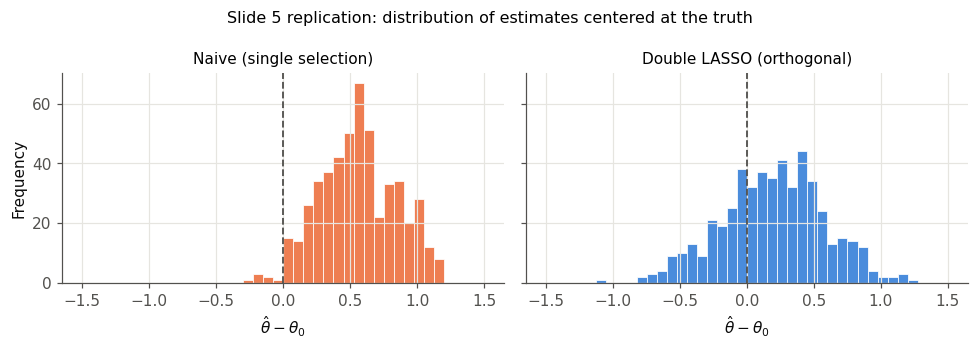

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
bins = np.linspace(-1.5, 1.5, 41)
for ax, col, name, c in [(axes[0], "naive", "Naive (single selection)", ORANGE),
                         (axes[1], "double", "Double LASSO (orthogonal)", BLUE)]:
    ax.hist(mc[col] - 1, bins=bins, color=c, alpha=0.85, edgecolor="white", linewidth=0.6)
    ax.axvline(0, color=INK2, lw=1.2, ls="--")
    ax.set_title(name, fontsize=10); ax.set_xlabel(r"$\hat\theta - \theta_0$")
axes[0].set_ylabel("Frequency")
fig.suptitle("Slide 5 replication: distribution of estimates centered at the truth", fontsize=10.5)
plt.tight_layout(); plt.show()

**Where does the naive bias come from? It is omitted-variable bias (slide 4).** In most replications the naive LASSO keeps exactly $\{Z_1\}$. OLS of $Y$ on $(D, Z_1)$ then omits $Z_{2},\dots,Z_p$, which are correlated with $D$. With $Z\sim N(0,I)$ the OVB formula is exact:
$$\text{bias} = \frac{\operatorname{Cov}(\tilde D,\ \sum_{j\ge2}\gamma_{0j}Z_j)}{\operatorname{Var}(\tilde D)}
= \frac{\sum_{j\ge 2}\pi_{0j}\gamma_{0j}}{\sum_{j\ge2}\pi_{0j}^2 + \operatorname{Var}(V)},\qquad \tilde D = D - \pi_{01}Z_1 .$$
Each omitted $Z_j$ is a *weak* predictor of $Y$ given $D$, but together they are a *strong* predictor of $D$ relative to the tiny residual variance $\operatorname{Var}(V) = 1/16$. Below we check the formula on the regression that *always* keeps only $Z_1$. (Averaging only over the draws where LASSO happened to keep $\{Z_1\}$ would condition on a data-dependent event, which shifts the average.)

In [6]:
j = np.arange(1, 101); g = 1 / j**2
ovb = (g[1:] @ g[1:]) / (g[1:] @ g[1:] + 1 / 16)
print(f"OVB formula, OLS of Y on (D, Z1)        : {ovb:.3f}")
print(f"MC bias, OLS of Y on (D, Z1) every draw   : {mc.ols_Z1.mean() - 1:.3f}")
print(f"MC bias, naive post-LASSO (all draws)     : {mc.naive.mean() - 1:.3f}   (it kept exactly {{Z1}} in {mc.only_Z1.mean():.0%} of draws)")

OVB formula, OLS of Y on (D, Z1)        : 0.568
MC bias, OLS of Y on (D, Z1) every draw   : 0.554
MC bias, naive post-LASSO (all draws)     : 0.560   (it kept exactly {Z1} in 77% of draws)


**An honest look at the Double LASSO row.** Double LASSO is far better (coverage around 91% versus well under 50% for the naive estimator), but at $n=100$ it is not perfectly centered: its bias is a non-trivial fraction of its standard deviation. We get the same numbers with `hdmpy`, so this is a property of the design, not of our code. Why? Two features of slide 5 make $n=100$ hard:

* the asymptotic variance $E[V_D^2U^2]/(E[V_D^2])^2 = 1/\operatorname{Var}(V) = 16$ is large, so the sd is $\approx 4/\sqrt{n} = 0.4$;
* the remaining bias is a **product** of the two nuisance errors (we will see this in Block 2), and with so little residual variation in $D$ even small errors in $\hat\pi$ matter.

The theory (slide 18) is asymptotic: under approximate sparsity with $s^2/n\to0$, bias/sd $\to 0$. Let's watch it happen while $p=100$ stays fixed.

In [7]:
R_n = 200          # per sample size; raise to 1000 at home
rows = []
t0 = time.time()
for n in [100, 400, 1600]:
    est = []
    for r in range(R_n):
        Y, D, Z = dgp_slide5(n=n, p=100, seed=10_000 + r)
        a, sa, _ = naive_post_lasso(Y, D, Z)
        b, sb, _, _ = double_lasso(Y, D, Z)
        est.append([a, sa, b, sb])
    e = np.array(est)
    for name, k in [("Naive", 0), ("Double LASSO", 2)]:
        rows.append(dict(n=n, estimator=name, bias=e[:, k].mean() - 1, sd=e[:, k].std(),
                         **{"|bias|/sd": abs(e[:, k].mean() - 1) / e[:, k].std(),
                            "coverage 95%": np.mean(np.abs(e[:, k] - 1) / e[:, k + 1] < 1.96)}))
print(f"done in {time.time()-t0:.1f}s")
pd.DataFrame(rows).pivot(index="n", columns="estimator")

done in 5.4s


bias                  sd           |bias|/sd         \
estimator Double LASSO  Naive Double LASSO  Naive Double LASSO  Naive   
n                                                                       
100              0.154  0.583        0.392  0.273        0.392  2.137   
400              0.069  0.573        0.187  0.148        0.369  3.869   
1600             0.011  0.274        0.103  0.171        0.102  1.601   

          coverage 95%         
estimator Double LASSO  Naive  
n                              
100              0.930  0.415  
400              0.950  0.020  
1600             0.945  0.295

**Read the numbers.** For double LASSO, |bias|/sd shrinks as $n$ grows and coverage sits near 95%. The naive estimator's coverage stays far below 95% at every $n$, even though its bias eventually falls (with more data LASSO keeps more controls). The naive bias does not shrink *faster than* $1/\sqrt n$, so the confidence interval never catches up. **"Consistent" is not enough for inference; we need bias $= o(n^{-1/2})$.** That is what orthogonality buys.

<details><summary><b>Quick check (answer)</b>: Why does double LASSO keep the controls the naive method drops?</summary>

Because it also asks "which $Z$'s predict $D$?" A confounder only has to be strong in **one** of the two equations to be kept. Formally, the remaining bias involves only controls omitted from **both** equations, weighted by the product $\pi_{0j}\cdot(\text{coefficient in the } Y\text{-on-}Z\text{ equation})$.
</details>

## 2. Neyman orthogonality, visually (slides 6–8, 16) · 9 min

Slides 6–8: the estimator solves $\frac1n\sum_i g(X_i;\hat\theta,\hat\gamma)=0$. If $\hat\gamma$ is off by a perturbation, how far does the implied $\theta$ move? Orthogonality says: **not at first order**, $\ \partial_\gamma E[g(X;\theta_0,\gamma)]|_{\gamma_0}=0$.

Let's make that concrete with the *direction LASSO actually errs in*, **shrinkage toward zero**. Write the nuisance as $(1-t)\times$ truth, for $t\in[0,1]$:

* **Naive score** (slide 8): $g = (Y - D\theta - Z^\top\gamma)D$ with $\gamma=(1-t)\gamma_0$. Solving $E[g]=0$:
$$\theta_{\text{naive}}(t) = \theta_0 + t\,\frac{\gamma_0^\top\pi_0}{\pi_0^\top\pi_0 + \sigma_V^2}\qquad\Rightarrow\ \text{bias is } \mathbf{linear}\text{ in } t.$$
* **Orthogonal (partialling-out) score** (slide 16): $g=\{(Y-Z^\top\beta)-(D-Z^\top\pi)\theta\}(D-Z^\top\pi)$ with $(\beta,\pi) = (1-t)(\beta_0,\pi_0)$, where $\beta_0 = \gamma_0 + \theta_0\pi_0$ is the reduced-form coefficient. Using $Z\sim N(0,I)$:
$$\theta_{\text{orth}}(t) = \frac{\theta_0\sigma_V^2 + t^2\,\beta_0^\top\pi_0}{\sigma_V^2 + t^2\,\pi_0^\top\pi_0}\qquad\Rightarrow\ \text{bias is } \mathbf{quadratic}\text{ in } t.$$

(Both lines are short derivations: expand the moment, use $E[ZZ^\top]=I$ and $E[ZV]=E[ZU]=0$. Try it at home; it is the slide 16 product-rule calculation evaluated along a path.)

A log–log plot makes "first order vs. second order" visible as **slope 1 vs. slope 2**.

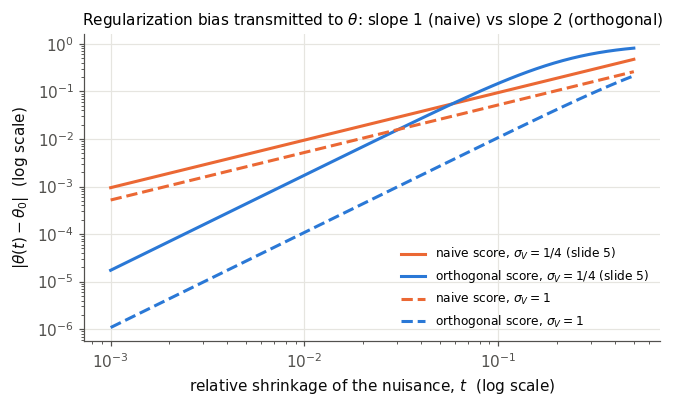

t=0.01  sigma_V=1/4: naive bias 0.0095, orth bias 0.0017  |  sigma_V=1: naive 0.0052, orth 0.0001
t=0.05  sigma_V=1/4: naive bias 0.0473, orth bias 0.0415  |  sigma_V=1: naive 0.0260, orth 0.0027
t=0.1   sigma_V=1/4: naive bias 0.0945, orth bias 0.1476  |  sigma_V=1: naive 0.0520, orth 0.0107


In [8]:
def implied_theta(t, sigma_V, theta0=1.0, p=100):
    j = np.arange(1, p + 1); g0 = pi0 = 1 / j**2; b0 = g0 + theta0 * pi0
    naive = theta0 + t * (g0 @ pi0) / (pi0 @ pi0 + sigma_V**2)
    orth = (theta0 * sigma_V**2 + t**2 * (b0 @ pi0)) / (sigma_V**2 + t**2 * (pi0 @ pi0))
    return naive, orth

t = np.logspace(-3, np.log10(0.5), 60)
fig, ax = plt.subplots(figsize=(6.2, 3.8))
for sV, ls, lab in [(0.25, "-", r"$\sigma_V = 1/4$ (slide 5)"), (1.0, "--", r"$\sigma_V = 1$")]:
    nv, orth = implied_theta(t, sV)
    ax.loglog(t, np.abs(nv - 1), color=ORANGE, ls=ls, label=f"naive score, {lab}")
    ax.loglog(t, np.abs(orth - 1), color=BLUE, ls=ls, label=f"orthogonal score, {lab}")
ax.set_xlabel("relative shrinkage of the nuisance, $t$  (log scale)")
ax.set_ylabel(r"$|\theta(t) - \theta_0|$  (log scale)")
ax.set_title("Regularization bias transmitted to $\\theta$: slope 1 (naive) vs slope 2 (orthogonal)", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

for tt in [0.01, 0.05, 0.1]:
    a1, b1 = implied_theta(tt, 0.25); a2, b2 = implied_theta(tt, 1.0)
    print(f"t={tt:<5} sigma_V=1/4: naive bias {a1-1:.4f}, orth bias {b1-1:.4f}  |  sigma_V=1: naive {a2-1:.4f}, orth {b2-1:.4f}")

**Simulation check.** The formulas are population quantities. Approximate the population with one very large sample and solve each moment equation at $t = 0.1$:

In [9]:
Yb, Db, Zb = dgp_slide5(n=200_000, p=100, seed=99)
j = np.arange(1, 101); g0 = pi0 = 1 / j**2; b0 = g0 + pi0; tt = 0.1
th_naive = ((Yb - Zb @ ((1 - tt) * g0)) @ Db) / (Db @ Db)
vY, vD = Yb - Zb @ ((1 - tt) * b0), Db - Zb @ ((1 - tt) * pi0)
th_orth = (vY @ vD) / (vD @ vD)
print(f"big-sample: naive {th_naive:.4f}, orthogonal {th_orth:.4f}   |  formulas: naive {implied_theta(tt,0.25)[0]:.4f}, orthogonal {implied_theta(tt,0.25)[1]:.4f}")

big-sample: naive 1.0937, orthogonal 1.1466   |  formulas: naive 1.0945, orthogonal 1.1476


**Takeaways from the picture.**
1. **Zero slope at $t=0$** is the Neyman orthogonality condition. Regularization error of size $t$ moves the naive $\theta$ by $O(t)$ but the orthogonal $\theta$ by only $O(t^2)$.
2. **Why this delivers $\sqrt n$-inference.** LASSO errors shrink with $n$. If they shrink faster than $n^{-1/4}$, then $t^2 = o(n^{-1/2})$ and the bias is negligible relative to the standard error. The naive bias $O(t)$ would need $t = o(n^{-1/2})$, which no regularized learner delivers in high dimensions. This is the origin of the familiar "$n^{-1/4}$ rate" condition for the nuisances in DML (Chernozhukov et al., 2018, Sec. 3–4; for the partialling-out score the condition is on $\|\hat m - m_0\|\times(\|\hat m-m_0\| + \|\hat\ell-\ell_0\|)$).
3. **The constant in front of $t^2$ matters in finite samples.** With $\sigma_V = 1/4$ the orthogonal curve sits much higher, because the curvature scales like $\|\pi_0\|^2/\sigma_V^2$. It even crosses the naive line around $t\approx 0.05$: for nuisance errors that large, orthogonality has not kicked in yet, and the sample must be big enough to push errors to the left of the crossing. When there is little residual variation in $D$ (a near-overlap problem for the PLR model), even small errors in $\hat m$ matter. This is the finite-sample bias we saw in the $n=100$ Double LASSO row of Block 1.

> **Caveat (flagged).** Point 3 and the shrinkage parametrization are my own illustration, not from the slides. Real LASSO errors are not exactly proportional shrinkage, but any smooth error path gives the same slope-1 vs. slope-2 picture.

## 3. Cross-fitting (slides 9–12) · 13 min

Orthogonality handles *regularization* bias. A second bias appears when the **same observations** are used to fit the nuisance and to evaluate the score: a flexible learner partly **memorizes** $Y_i$, so the in-sample residual $Y_i - \hat\ell(Z_i)$ is shrunk toward zero, and it is shrunk in the part that carries the causal signal, $\theta_0 V_{D,i}$.

We use the partially linear DGP behind slide 23 (`make_plr_CCDDHNR2018` in DoubleML, written out here so you can see it):
$$D = m_0(Z) + V,\quad Y = \theta_0 D + g_0(Z) + U,\quad m_0(z) = z_1 + \tfrac14\tfrac{e^{z_3}}{1+e^{z_3}},\ \ g_0(z) = \tfrac{e^{z_1}}{1+e^{z_1}} + \tfrac14 z_3,$$
$Z\sim N(0,\Sigma)$ with $\Sigma_{jk} = 0.7^{|j-k|}$, $p=20$, $n=500$, $\theta_0 = 0.5$.

In [10]:
def dgp_plr(n=500, p=20, theta=0.5, seed=0):
    rng = np.random.default_rng(seed)
    idx = np.arange(p)
    Z = rng.multivariate_normal(np.zeros(p), 0.7 ** np.abs(idx[:, None] - idx[None, :]), size=n)
    m0 = Z[:, 0] + 0.25 * np.exp(Z[:, 2]) / (1 + np.exp(Z[:, 2]))
    g0 = np.exp(Z[:, 0]) / (1 + np.exp(Z[:, 0])) + 0.25 * Z[:, 2]
    D = m0 + rng.standard_normal(n)
    Y = theta * D + g0 + rng.standard_normal(n)
    return Y, D, Z, theta * m0 + g0, m0          # also return l0 = E[Y|Z] and m0 = E[D|Z]

def dml_plr(Y, D, Z, make_l, make_m, K=5, seed=0, return_resid=False):
    # Partialling-out DML for the PLR model (slide 22). K=1 means NO cross-fitting (full sample).
    n = len(Y)
    if K == 1:
        l_hat = make_l().fit(Z, Y).predict(Z)
        m_hat = make_m().fit(Z, D).predict(Z)
    else:
        l_hat, m_hat = np.zeros(n), np.zeros(n)
        for tr, te in KFold(K, shuffle=True, random_state=seed).split(Z):
            l_hat[te] = make_l().fit(Z[tr], Y[tr]).predict(Z[te])
            m_hat[te] = make_m().fit(Z[tr], D[tr]).predict(Z[te])
    vY, vD = Y - l_hat, D - m_hat
    theta = (vY @ vD) / (vD @ vD)
    U = vY - theta * vD
    se = np.sqrt(np.mean(vD**2 * U**2) / np.mean(vD**2) ** 2 / n)
    return (theta, se, vY, vD) if return_resid else (theta, se)

deep_rf = lambda: RandomForestRegressor(n_estimators=50, min_samples_leaf=1, max_features=1.0, n_jobs=-1, random_state=0)
lasso_cv = lambda: LassoCV(cv=5)

**The mechanism on one dataset.** A fully grown random forest for $\ell_0(Z)=E[Y|Z]$; a LASSO for $m_0(Z) = E[D|Z]$ (a perfectly reasonable practitioner choice: different learners for different nuisances). Compare the residual $\hat V_Y$ with the true $V_Y = Y - \ell_0(Z)$:

**Why the in-sample estimate collapses (a back-of-the-envelope).** A fully grown forest predicts $Y_i$ partly *with* $Y_i$: $\hat\ell(Z_i) - \ell_0(Z_i) \approx w\,V_{Y,i}$ for a "self-weight" $w$, so $\hat V_{Y,i}\approx(1-w)(\theta_0V_{D,i}+U_i)$. LASSO with $p=20 \ll n$ barely memorizes, so $\hat V_{D,i}\approx V_{D,i}$. Then
$$\hat\theta \approx \frac{\sum (1-w)\,\theta_0 V_{D,i}^2}{\sum V_{D,i}^2} = (1-w)\,\theta_0 .$$
The slope in the left panel *is* an estimate of $1-w$; multiply it by $0.5$ and you get roughly the in-sample $\hat\theta$. Out-of-fold, $\hat\ell_{-k}$ has never seen $Y_i$, so $w=0$.

> **Flag.** This self-weight heuristic is my own back-of-the-envelope (it treats the forest like a linear smoother), not the formal argument. The formal one (Chernozhukov et al., 2018, Sec. 3) bounds the term $\frac{1}{\sqrt n}\sum_i(\hat\ell(Z_i)-\ell_0(Z_i))V_{D,i}$, which has mean zero when $\hat\ell$ is trained on other folds but not when it is trained on observation $i$ itself.

Now the Monte Carlo version of slide 9's figure: the distribution of $t = (\hat\theta-\theta_0)/\widehat{se}$ should look like $N(0,1)$.

In [12]:
R_cf = 50          # ~1 min; use 500 at home for a smooth histogram
t0 = time.time()
res = []
for r in range(R_cf):
    Y, D, Z, _, _ = dgp_plr(seed=100 + r)
    res.append([*dml_plr(Y, D, Z, deep_rf, lasso_cv, K=1), *dml_plr(Y, D, Z, deep_rf, lasso_cv, K=5, seed=r)])
res = np.array(res)
print(f"{R_cf} replications in {time.time()-t0:.0f}s")
tab3 = pd.DataFrame({"No cross-fitting": summarize(res[:, 0], res[:, 1], 0.5),
                     "5-fold cross-fitting": summarize(res[:, 2], res[:, 3], 0.5)}).T
tab3

50 replications in 19s


,bias,sd,rmse,mean se,coverage 95%
No cross-fitting,-0.317,0.019,0.317,0.018,0.00
5-fold cross-fitting,-0.006,0.053,0.053,0.047,0.96


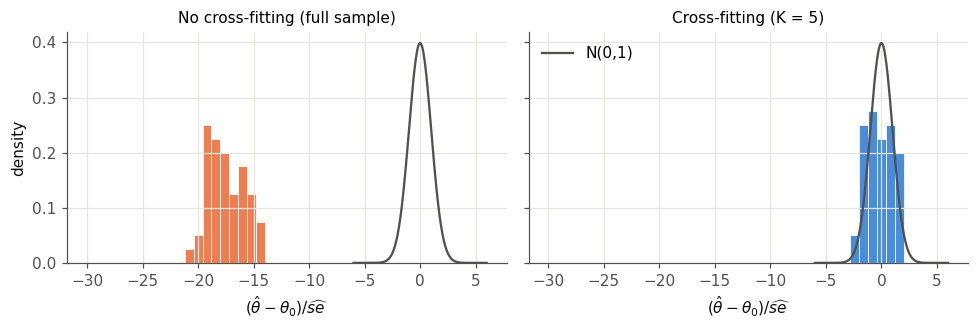

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.1), sharey=True)
grid = np.linspace(-6, 6, 200)
for ax, k, name, c in [(axes[0], 0, "No cross-fitting (full sample)", ORANGE), (axes[1], 2, "Cross-fitting (K = 5)", BLUE)]:
    tstat = (res[:, k] - 0.5) / res[:, k + 1]
    ax.hist(np.clip(tstat, -30, 6), bins=np.linspace(-30, 6, 46), density=True, color=c, alpha=0.85, edgecolor="white", lw=0.6)
    ax.plot(grid, norm.pdf(grid), color=INK2, lw=1.5, label="N(0,1)")
    ax.set_title(name, fontsize=10); ax.set_xlabel(r"$(\hat\theta-\theta_0)/\widehat{se}$")
axes[0].set_ylabel("density"); axes[1].legend()
plt.tight_layout(); plt.show()

**Read the numbers.** Without cross-fitting the estimator is centered far from $\theta_0$ (the $t$-statistics pile up around large negative values) and the 95% interval essentially never covers. With cross-fitting the same learners give an approximately centered, approximately normal $t$-statistic.

**Try at home (2 lines of code).** Use a deep forest for *both* nuisances. The in-sample shrinkage now hits $\hat V_Y$ and $\hat V_D$ in similar proportions and largely cancels in the ratio, so the no-cross-fitting estimator can look fine. That is luck, not a guarantee: it breaks as soon as the two learners overfit differently. Cross-fitting makes the procedure valid **without** needing that luck. (The other motivation on slide 9, relaxing stochastic-equicontinuity / Donsker conditions, is the theoretical side of the same coin.)

### 3b. How many folds, and median aggregation (slides 11–12)

Results depend on the random split. Chernozhukov et al. (2018) recommend repeating the split $S$ times and aggregating:
$$\hat\theta^*=\operatorname{med}_s\hat\theta_s,\qquad \hat V^*_s = \hat V_s + (\hat\theta_s-\hat\theta^*)^2,\qquad \hat V^* = \text{the }\hat V^*_s\text{ with median norm}.$$
(For a scalar $\theta$, "median spectral norm" is just the median of the $\hat V^*_s$.) Below: one dataset, the slide 23 random forest for both nuisances, $S=10$ splits.

In [14]:
slide_rf = lambda: RandomForestRegressor(n_estimators=100, max_features=20, max_depth=5, min_samples_leaf=2, n_jobs=-1, random_state=0)
Y, D, Z, _, _ = dgp_plr(seed=7)
S = 10
splits = pd.DataFrame([dml_plr(Y, D, Z, slide_rf, slide_rf, K=5, seed=s) for s in range(S)], columns=["theta_s", "se_s"])
theta_star = splits.theta_s.median()
V_adj = splits.se_s**2 + (splits.theta_s - theta_star) ** 2       # slide 12, step 3
se_star = np.sqrt(np.median(V_adj))                               # slide 12, step 4 (scalar case)
print(splits.round(4).T.to_string())
print(f"\nrange of theta_s across splits: [{splits.theta_s.min():.3f}, {splits.theta_s.max():.3f}];  sd across splits = {splits.theta_s.std():.4f}")
print(f"median-aggregated: theta* = {theta_star:.4f}, se* = {se_star:.4f}   (median unadjusted se = {splits.se_s.median():.4f})")

             0      1      2      3      4      5      6      7      8      9
theta_s  0.473  0.458  0.489  0.475  0.475  0.476  0.473  0.492  0.502  0.493
se_s     0.040  0.043  0.042  0.041  0.042  0.040  0.043  0.041  0.041  0.041

range of theta_s across splits: [0.458, 0.502];  sd across splits = 0.0129
median-aggregated: theta* = 0.4757, se* = 0.0434   (median unadjusted se = 0.0412)


Here the split-to-split standard deviation is roughly a third of the standard error, so the adjustment raises $\widehat{se}$ only modestly. With small $n$ or very adaptive learners split noise can be a much larger share. Reporting a single lucky split would then overstate precision, and the median plus adjusted variance protects you. **Folds:** larger $K$ trains each nuisance on more data ($1-1/K$ of the sample) at higher computational cost; $K=5$ or $10$ is the usual compromise (slide 11).

**Cross-check with the package from slide 23.** `DoubleMLPLR` implements the same partialling-out score with $K$-fold cross-fitting and `n_rep` repeated splits. We hand it **our** ten splits, so every number is comparable. Two version notes:
* In recent DoubleML (0.11 here) the slide's `from doubleml.datasets import make_plr_CCDDHNR2018` fails; the generator now lives in `doubleml.plm.datasets`.
* DoubleML's point estimate is the median $\hat\theta^*$, as on slide 12. Its aggregated standard error, however, comes from the median of the upper confidence bounds, $\big(\operatorname{med}_s\{\hat\theta_s + 1.96\,\widehat{se}_s\} - \hat\theta^*\big)/1.96$, not from the slide 12 variance rule. The two are close but not identical.

In [15]:
try:
    import doubleml as dml
    df = pd.DataFrame(Z, columns=[f"X{k+1}" for k in range(Z.shape[1])]).assign(y=Y, d=D)
    obj = dml.DoubleMLPLR(dml.DoubleMLData(df, "y", "d"), slide_rf(), slide_rf(), n_folds=5, n_rep=S,
                          draw_sample_splitting=False)
    obj.set_sample_splitting(all_smpls=[list(KFold(5, shuffle=True, random_state=s).split(Z)) for s in range(S)])
    obj.fit()
    print(f"doubleml {dml.__version__}")
    print("max |our theta_s - DoubleML theta_s| :", np.abs(obj.all_coef.ravel() - splits.theta_s.values).max().round(10))
    print(f"DoubleML median theta = {obj.coef[0]:.4f}   (ours {theta_star:.4f})")
    print(f"DoubleML aggregated se = {obj.se[0]:.4f}  vs slide-12 rule {se_star:.4f}")
except ImportError:
    print("pip install doubleml   # optional cross-check")

pip install doubleml   # optional cross-check


## 4. Model-based DML with nonlinear learners (slides 20–25) · 10 min

Double LASSO assumes $E[Y|Z]$ and $E[D|Z]$ are (approximately sparse) **linear** functions. The PLR model $Y = D\theta_0 + g_0(Z) + U$ (slide 21) lets $g_0$ and $m_0$ be arbitrary. The same partialling-out score is Neyman orthogonal in the **Gateaux** sense (slide 20): for every direction $\delta(Z)$,
$$\tfrac{d}{dt}E\big[\{(Y-\ell_0(Z) - t\delta(Z)) - (D-m_0(Z))\theta_0\}(D-m_0(Z))\big]\Big|_{t=0} = -E[\delta(Z)V_D] = 0 .$$
A one-line numerical check with a nonlinear direction $\delta(z) = \sin(z_2) + z_1^2$, compared with the non-orthogonal score $(Y - D\theta_0 - g(Z))D$:

In [16]:
def dgp_nonlin(n=2000, p=50, theta=0.5, seed=0):
    # High-dimensional PLR with nonlinear confounding through Z1 (a jump) and Z2 (a symmetric U-shape).
    rng = np.random.default_rng(seed)
    Z = rng.standard_normal((n, p))
    m0 = 0.5 * (Z[:, 1] ** 2 - 1) + 0.5 * (Z[:, 0] > 0)
    g0 = 0.5 * (Z[:, 1] ** 2 - 1) + 1.0 * (Z[:, 0] > 0) + 0.5 * Z[:, 2]
    D = m0 + rng.standard_normal(n)
    Y = theta * D + g0 + rng.standard_normal(n)
    return Y, D, Z, theta * m0 + g0, m0, g0

Yb, Db, Zb, l0b, m0b, g0b = dgp_nonlin(n=1_000_000, p=5, seed=1)
delta = np.sin(Zb[:, 1]) + Zb[:, 0] ** 2
h = 1e-3
orth = lambda t_l, t_m: np.mean(((Yb - l0b - t_l * delta) - (Db - m0b - t_m * delta) * 0.5) * (Db - m0b - t_m * delta))
nonorth = lambda t_g: np.mean((Yb - 0.5 * Db - g0b - t_g * delta) * Db)
mc_se = np.std(delta * (Db - m0b)) / np.sqrt(len(Db))
print(f"(simulation standard error of these derivatives is about {mc_se:.4f})")
print(f"d/dt orthogonal score, direction in l : {(orth(h,0) - orth(-h,0)) / (2*h):+.4f}")
print(f"d/dt orthogonal score, direction in m : {(orth(0,h) - orth(0,-h)) / (2*h):+.4f}")
print(f"d/dt NON-orthogonal score, direction in g: {(nonorth(h) - nonorth(-h)) / (2*h):+.4f}   (= -E[delta(Z) D])")

(simulation standard error of these derivatives is about 0.0019)
d/dt orthogonal score, direction in l : +0.0017
d/dt orthogonal score, direction in m : -0.0025
d/dt NON-orthogonal score, direction in g: -0.2508   (= -E[delta(Z) D])


Now estimate $\theta_0=0.5$ in a high-dimensional design ($n=2000$, $p=50$ controls, only 3 relevant) with **nonlinear** confounding: a jump in $Z_1$ and a U-shape in $Z_2$. A linear learner cannot see the U-shape at all, because $\operatorname{Cov}(Z_2^2, Z_2)=0$. We mirror slide 25: the same DML recipe with different nuisance learners, reporting the out-of-fold $R^2$ of each nuisance.

In [17]:
learners = {
    "Double LASSO": lambda: make_pipeline(StandardScaler(), LassoCV(cv=5)),
    "Random forest": lambda: RandomForestRegressor(n_estimators=200, max_features=0.5, min_samples_leaf=10, n_jobs=-1, random_state=0),
    "Boosting": lambda: HistGradientBoostingRegressor(learning_rate=0.05, max_iter=500, max_depth=3, early_stopping=True,
                                                      validation_fraction=0.2, n_iter_no_change=20, random_state=0),
    "Neural net (200-20, ReLU)": lambda: make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(200, 20), alpha=10.0,
                                                      early_stopping=True, validation_fraction=0.15, n_iter_no_change=30, max_iter=1000, random_state=0)),
}
Y, D, Z, l0, m0, _ = dgp_nonlin(seed=2026)
rows = []
for name, mk in learners.items():
    t0 = time.time()
    th, se, vY, vD = dml_plr(Y, D, Z, mk, mk, K=5, seed=0, return_resid=True)
    rows.append({"learner": name, "estimate": th, "se": se, "CI low": th - 1.96 * se, "CI high": th + 1.96 * se,
                 "R2_Y (oof)": 1 - np.mean(vY**2) / np.var(Y), "R2_D (oof)": 1 - np.mean(vD**2) / np.var(D),
                 "secs": time.time() - t0})
tab4 = pd.DataFrame(rows).set_index("learner")
print(f"oracle R2_Y = {1 - np.mean((Y-l0)**2)/np.var(Y):.2f},  oracle R2_D = {1 - np.mean((D-m0)**2)/np.var(D):.2f},  truth theta0 = 0.5")
tab4

oracle R2_Y = 0.60,  oracle R2_D = 0.36,  truth theta0 = 0.5


,estimate,se,CI low,CI high,R2_Y (oof),R2_D (oof),secs
learner,,,,,,,
Double LASSO,0.845,0.027,0.793,0.897,0.183,0.035,0.209
Random forest,0.548,0.026,0.497,0.599,0.522,0.318,3.119
Boosting,0.533,0.024,0.486,0.581,0.530,0.311,3.655
"Neural net (200-20, ReLU)",0.578,0.024,0.531,0.625,0.439,0.261,4.328


**Where does the Double LASSO estimate converge?** Partialling out with *linear* projections converges to a pseudo-true value, not to $\theta_0$. Approximate it with a huge sample and OLS (no regularization noise at all):

In [18]:
Yb, Db, Zb, *_ = dgp_nonlin(n=300_000, p=50, seed=5)
vY = Yb - LinearRegression().fit(Zb, Yb).predict(Zb)
vD = Db - LinearRegression().fit(Zb, Db).predict(Zb)
print(f"probability limit of linear partialling-out: {(vY @ vD) / (vD @ vD):.3f}   (truth 0.5)")

probability limit of linear partialling-out: 0.855   (truth 0.5)


**Read the table (compare with slides 24–25).**
* The estimates broadly track $R^2_D$ and $R^2_Y$: learners that remove more confounding variation in **both** equations land closer to $\theta_0$. (What matters is the *product* of the two nuisance errors, so the ordering need not match either column exactly.) The R² row is a useful diagnostic in practice, exactly as on slide 25.
* Double LASSO is not "wrong code". It converges to the linear-projection limit above, because the U-shape in $Z_2$ is invisible to a linear $m$ *and* a linear $\ell$, so it stays in both residuals and they co-move. This is **misspecification**, which orthogonality cannot fix: orthogonality protects against *small* nuisance errors, not against nuisances that converge to the wrong function.
* Boosting and the forest capture the jump and the U-shape. Their remaining error is a *product* of two moderate nuisance errors, so it is much smaller. Standard errors are similar across learners; what differs is **where the interval is centered**.

<details><summary><b>Discussion (answer)</b>: The toy-car application (slide 25) moves from −0.064 (Double LASSO) to about −0.13 (RF / deep learning). Which estimate would you report?</summary>

The flexible-learner estimates, with the R² table as supporting evidence: they explain substantially more of the variation in both price and sales, so less confounding is left in the residuals. A good habit is to report several learners. If they agree, conclusions do not hinge on one functional form; if they disagree, the R² diagnostics tell you which to trust.
</details>

In [19]:
# Optional (~40 s): is the Boosting row a fluke? A mini Monte Carlo for Double LASSO vs Boosting.
R_mini = 20
out = {k: [] for k in ["Double LASSO", "Boosting"]}
t0 = time.time()
for r in range(R_mini):
    Y, D, Z, *_ = dgp_nonlin(seed=500 + r)
    for k in out:
        out[k].append(dml_plr(Y, D, Z, learners[k], learners[k], K=5, seed=r))
print(f"{R_mini} replications in {time.time()-t0:.0f}s")
pd.DataFrame({k: summarize(np.array(v)[:, 0], np.array(v)[:, 1], 0.5) for k, v in out.items()}).T

20 replications in 71s


,bias,sd,rmse,mean se,coverage 95%
Double LASSO,0.354,0.024,0.355,0.027,0.00
Boosting,0.029,0.027,0.039,0.025,0.95


## 5. Wrap-up · 2 min

1. **ML nuisances + a naive score = biased inference.** Single-selection post-LASSO drops controls that matter for $D$; that is omitted-variable bias (slides 4–5).
2. **Orthogonality** makes the moment insensitive to nuisance errors at first order: bias $O(t)\to O(t^2)$. Nuisance errors only need to vanish faster than $n^{-1/4}$ (slides 6–8, 16).
3. **Cross-fitting** removes overfitting bias. Never evaluate the score on the observations used to train the nuisance; repeat splits and take medians (slides 9–12).
4. **PLR-DML** works with any learner. Flexible learners pay off when confounding is nonlinear, and out-of-fold $R^2$ is your diagnostic (slides 20–25).

**Next Friday (Nov 13).** Everything today exploited the *model* (linearity in $D$) to build the orthogonal score. What if the target is an ATE, LATE, or DiD-ATT with **no** parametric model? The **Riesz representer** gives an orthogonal score *automatically* (slides 26–50).

**References.** Belloni, Chernozhukov & Hansen (2014); Chernozhukov, Chetverikov, Demirer, Duflo, Hansen, Newey & Robins (2018, *Econometrics Journal*); Chernozhukov, Hansen, Kallus, Spindler & Syrgkanis (2024), *Applied Causal Inference Powered by ML and AI*, Ch. 4 & 10; Bach, Chernozhukov, Kurz & Spindler, DoubleML for Python (JMLR 2022).